# Example 13.2: Inverse MLP – Parameter Prediction from Trajectory Features
**Chapter 13 – Neural Networks for Synthesis of Four-Bar Mechanisms**

MLP 6→64→64→3 maps geometric features of the curve → lengths (a, b, c).

In [2]:
from numpy import *
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

random.seed(7)
D_FIXED=85.; LP,DELTA=50.,pi/5

def curva(a,b,c,d,n=72):
    ths=linspace(0,2*pi,n,endpoint=False)
    xs,ys=zeros(n),zeros(n)
    for i,th2 in enumerate(ths):
        x2=a*cos(th2)-d; y2=a*sin(th2)
        r=sqrt(x2**2+y2**2)
        arg=clip((r**2+c**2-b**2)/(2*r*c),-1,1)
        th3=arctan2(y2,x2)+arccos(arg)
        xs[i]=a*cos(th2)+LP*cos(th3+DELTA)
        ys[i]=a*sin(th2)+LP*sin(th3+DELTA)
    return xs,ys

def grashof(a,b,c,d):
    s=sorted([a,b,c,d]); return s[0]+s[3]<=s[1]+s[2]

def feats(xs,ys):
    mx,my=mean(xs),mean(ys); sx,sy=std(xs)+1e-9,std(ys)+1e-9
    rho=mean((xs-mx)*(ys-my))/(sx*sy)
    return array([mx,my,sx,sy,rho,pi*sx*sy])

N=1500; Xf,Yp,curvas=[],[],[]
it=0
while len(Xf)<N and it<50000:
    it+=1
    a=random.uniform(25,90); b=random.uniform(40,120); c=random.uniform(40,120)
    if not grashof(a,b,c,D_FIXED): continue
    try:
        xs,ys=curva(a,b,c,D_FIXED)
        if any(isnan(xs)): continue
        Xf.append(feats(xs,ys)); Yp.append(array([a,b,c])/120.)
        curvas.append((xs,ys))
    except:
        continue

Xf=array(Xf); Yp=array(Yp)
print(f"Dataset: {len(Xf)} samples")
Xf_min=Xf.min(0); Xf_max=Xf.max(0)+1e-9
Xn=(Xf-Xf_min)/(Xf_max-Xf_min)
perm=random.permutation(len(Xn)); ntr=int(0.8*len(Xn))
Xtr,Ytr=Xn[perm[:ntr]],Yp[perm[:ntr]]
Xv,Yv=Xn[perm[ntr:]],Yp[perm[ntr:]]

def relu(z): return maximum(0,z)
def sig(z): return 1/(1+exp(-clip(z,-500,500)))
W1=random.randn(6,64)*sqrt(2/6); b1=zeros((1,64))
W2=random.randn(64,64)*sqrt(2/64); b2=zeros((1,64))
W3=random.randn(64,3)*sqrt(2/64); b3=zeros((1,3))
LR,LAM,BS=5e-4,5e-5,32

loss_history = []

for ep in range(400):
    perm2=random.permutation(ntr)
    epoch_loss = 0.0
    batches = 0
    for s in range(0,ntr,BS):
        ib=perm2[s:s+BS]; xb,yb=Xtr[ib],Ytr[ib]
        Z1=xb@W1+b1; A1=relu(Z1); Z2=A1@W2+b2; A2=relu(Z2)
        Z3=A2@W3+b3; A3=sig(Z3)

        # MSE Loss calculation
        loss = mean((A3 - yb)**2)
        epoch_loss += loss
        batches += 1

        n=len(xb); dA3=(A3-yb)/n; dZ3=dA3*A3*(1-A3)
        dW3=A2.T@dZ3; db3=dZ3.sum(0,keepdims=True)
        dA2=dZ3@W3.T; dZ2=dA2*(Z2>0)
        dW2=A1.T@dZ2; db2=dZ2.sum(0,keepdims=True)
        dA1=dZ2@W2.T; dZ1=dA1*(Z1>0)
        dW1=xb.T@dZ1; db1=dZ1.sum(0,keepdims=True)
        W1-=LR*(dW1+LAM*W1); b1-=LR*db1
        W2-=LR*(dW2+LAM*W2); b2-=LR*db2
        W3-=LR*(dW3+LAM*W3); b3-=LR*db3

    loss_history.append(epoch_loss / batches)
    if (ep+1)%80==0:
        def fwd(X): return sig(relu(relu(X@W1+b1)@W2+b2)@W3+b3)
        rmse=sqrt(mean((fwd(Xv)-Yv)**2))*120
        print(f"Epoch {ep+1:3d}  RMSE_val = {rmse:.2f} mm")

def fwd(X): return sig(relu(relu(X@W1+b1)@W2+b2)@W3+b3)
rmse=sqrt(mean((fwd(Xv)-Yv)**2))*120
print(f"\nFinal validation RMSE: {rmse:.2f} mm")

Dataset: 1500 samples
Epoch  80  RMSE_val = 23.17 mm
Epoch 160  RMSE_val = 21.36 mm
Epoch 240  RMSE_val = 19.96 mm
Epoch 320  RMSE_val = 18.79 mm
Epoch 400  RMSE_val = 17.80 mm

Final validation RMSE: 17.80 mm


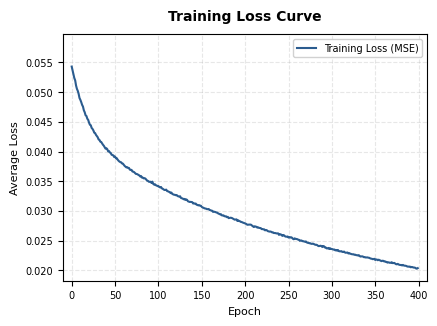

In [4]:
import matplotlib.pyplot as plt
import os
import glob

# 1. Automated Filename System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_13_2_mlp_inverse"
except Exception:
    notebook_name = "Figure_13_2_mlp_inverse"

# 2. Springer Quality Settings
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'

# 3. Figure Creation (Controlled single-column dimensions)
fig, ax = plt.subplots(figsize=(4.7, 3.2))

# 4. Plotting Loss Curve
ax.plot(loss_history, label='Training Loss (MSE)', color='#2b5c8f', linewidth=1.5)

# 5. Labels & Title in Academic English
ax.set_title('Training Loss Curve', fontsize=10, fontweight='bold', pad=10)
ax.set_xlabel('Epoch', fontsize=8)
ax.set_ylabel('Average Loss', fontsize=8)

# 6. Clean Grid and Limits
ax.grid(True, linestyle='--', alpha=0.3)
ax.tick_params(labelsize=7)
ax.set_xlim(-10, len(loss_history) + 10)

# Add visual margin to avoid overlap with upper labels
ax.set_ylim(min(loss_history) * 0.9, max(loss_history) * 1.1)

# 7. Legend
ax.legend(fontsize=7, loc='upper right', framealpha=0.9)

# 8. Mandatory Double Export and Show
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

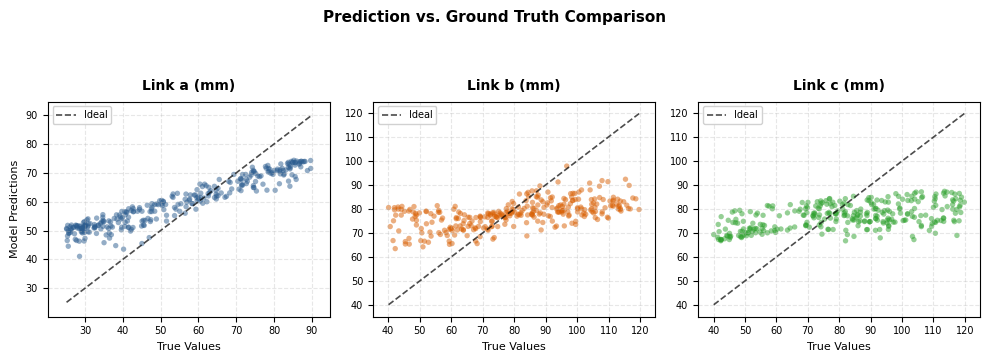

In [6]:
import matplotlib.pyplot as plt
import os
import glob
import numpy as np

# 1. Automated Filename System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '') + "_comparison"
    else:
        notebook_name = "Figure_13_2_mlp_comparison"
except Exception:
    notebook_name = "Figure_13_2_mlp_comparison"

# 2. Springer Quality Settings
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'

# 3. Model Predictions on Validation Set
Ypred = fwd(Xv) * 120.0  # Denormalize predictions
Ytrue_val = Yv * 120.0  # Denormalize actual values

# 4. Figure Creation (3 Horizontal Subplots for publication standards)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.5), sharey=False)
labels = ['Link a (mm)', 'Link b (mm)', 'Link c (mm)']
colors = ['#2b5c8f', '#d95f02', '#2ca02c']

for i, ax in enumerate(axs):
    # Scatter comparison
    ax.scatter(Ytrue_val[:, i], Ypred[:, i], alpha=0.5, color=colors[i], edgecolors='none', s=15)

    # Identity Line (Perfect prediction) using explicit numpy min/max
    ideal_min = float(np.minimum(Ytrue_val[:, i].min(), Ypred[:, i].min()))
    ideal_max = float(np.maximum(Ytrue_val[:, i].max(), Ypred[:, i].max()))
    ax.plot([ideal_min, ideal_max], [ideal_min, ideal_max], 'k--', alpha=0.7, linewidth=1.2, label='Ideal')

    # Formatting
    ax.set_title(labels[i], fontsize=10, fontweight='bold', pad=8)
    ax.set_xlabel('True Values', fontsize=8)
    if i == 0:
        ax.set_ylabel('Model Predictions', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.tick_params(labelsize=7)

    # Expand margins slightly to avoid edge cropping
    ax.set_xlim(ideal_min - 5, ideal_max + 5)
    ax.set_ylim(ideal_min - 5, ideal_max + 5)
    ax.legend(fontsize=7, loc='upper left', framealpha=0.9)

plt.suptitle('Prediction vs. Ground Truth Comparison', fontsize=11, fontweight='bold', y=1.02)
tight_layout_params = {'rect': [0, 0, 1, 0.95]}
plt.tight_layout(**tight_layout_params)

# 5. Mandatory Double Export and Show
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()